# Interferometry: phase shifting and Fourier fringe analysis

An interferometer superposes a test beam, which carries the wavefront error
$W$ of the optics under test as the phase $\varphi = kW$, with a reference beam.
The camera sees the two-beam interferogram

$$I = |E_\mathrm{test} + E_\mathrm{ref}\,e^{i\delta}|^2 = a + b\cos(\varphi - \delta)
= a\,[1 + \gamma\cos(\varphi - \delta)],$$

with the bias $a$, the fringe amplitude $b$ and the modulation (visibility)
$\gamma = b/a$. One frame has three unknowns per pixel, so the phase needs
either several frames with known phase shifts $\delta_j$ (*phase-shifting
interferometry*, PSI) or a single frame with a tilt carrier whose spectrum
separates the information (*Fourier-transform method*, Takeda 1982).

`pyoptics.interferometry` offers:

| Function | Frames | Shifts |
|---|---|---|
| `psi_n_step(frames, shifts)` | $N \ge 3$ | any known shifts (least squares) |
| `psi_4_step(frames)` | 4 | $0, \pi/2, \pi, 3\pi/2$ |
| `psi_carre(frames)` | 4 | $\pm\alpha/2, \pm 3\alpha/2$, $\alpha$ unknown |
| `psi_hariharan(frames)` | 5 | $0, \pm\pi/2, \pm\pi$, insensitive to linear shift errors |
| `fourier_fringe_analysis(I, x, y)` | 1 | tilt carrier $k_c$ |

All of them return the wrapped phase and the modulation $\gamma$; the phase
is then unwrapped with `pyoptics.unwrap`. Simulation helpers:
`zernike_phase()`, `interferogram()`, `interfere()` and `phase_shifts()`.

**Sign convention.** pyoptics fields vary as $e^{i(\mathbf{k}\cdot\mathbf{r} - \omega t)}$,
so a wavefront that runs ahead has $\varphi > 0$ (phase $= +k\cdot$OPD). The
algorithms return $\varphi = \arg(E_\mathrm{test}E_\mathrm{ref}^*)$. A phase shift
$\delta > 0$ delays the reference, hence $\cos(\varphi - \delta)$. Many
textbooks write $\cos(\varphi + \delta)$; their formulas give $-\varphi$ here.
Image stacks have the frame index last, as everywhere in `pyoptics.processing`.

In [1]:
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import binary_erosion

from pyoptics.bases import FringeZernikes
from pyoptics.fft import FT
from pyoptics.interferometry import (zernike_phase, interferogram, interfere,
                                     phase_shifts, psi_n_step, psi_4_step,
                                     psi_carre, psi_hariharan,
                                     shift_error_sensitivity,
                                     fourier_fringe_analysis, find_carrier)
from pyoptics.processing import CameraNoiser
from pyoptics.unwrap import wrap, unwrap_ls
from pyoptics.utils import grid2d, freq_grid

plt.rcParams.update({"figure.dpi": 80, "image.origin": "lower", "font.size": 11})


def show(ax, img, title, cmap="viridis", **kwargs):
    im = ax.imshow(img, extent=extent, cmap=cmap, **kwargs)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    return im


def nan_outside(img, mask):
    return np.where(mask, img, np.nan)


N = 256
x, y, X, Y = grid2d(-1, 1, -1, 1, N)
extent = (x[0], x[-1], y[0], y[-1])

## 1. The test wavefront and its interferograms

A wavefront in a pupil of radius 0.9 with 2.5 waves of defocus plus
astigmatism, coma and spherical aberration (Fringe Zernike coefficients in
waves). Four phase-shifted frames with shifts $0, \pi/2, \pi, 3\pi/2$: with
every step of $\pi/2$ the fringes move by a quarter period, towards larger
$\varphi$, i.e. outwards for this wavefront that runs ahead at the edge.

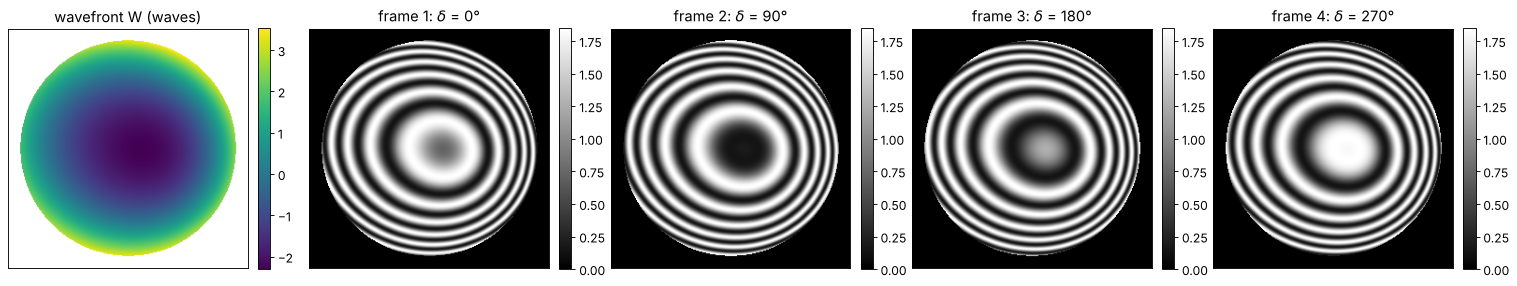

In [2]:
coeffs = {4: 2.5, 5: -0.6, 6: 0.3, 7: 0.4, 9: 0.25}       # waves
phi, pupil = zernike_phase(x, y, list(coeffs.values()), 0.9, indices=list(coeffs))
gamma_true = 0.85

shifts = phase_shifts(4)
frames = interferogram(phi, visibility=gamma_true, shift=shifts) * pupil[..., None]

fig, axes = plt.subplots(1, 5, figsize=(19, 3.6))
show(axes[0], nan_outside(phi/(2*np.pi), pupil), "wavefront W (waves)")
for j in range(4):
    show(axes[j + 1], frames[..., j], r"frame %d: $\delta$ = %d°" % (j + 1, np.degrees(shifts[j])),
         cmap="gray")
plt.tight_layout()

`interfere()` builds the same frames from two complex fields: here the test
field $e^{i\varphi}$ and a weaker reference. The visibility is then
$\gamma = 2|E_t||E_r|/(|E_t|^2 + |E_r|^2)$.

In [3]:
E_ref = 0.5
frames_fields = interfere(np.exp(1j*phi), E_ref, shifts)
rec, gamma = psi_4_step(frames_fields)
print("max phase error: %.1e rad" % np.max(np.abs(wrap(rec - phi))[pupil]))
print("modulation: %.4f (expected %.4f)" % (gamma[pupil].mean(), 2*E_ref/(1 + E_ref**2)))

max phase error: 1.8e-15 rad
modulation: 0.8000 (expected 0.8000)


## 2. Phase-shifting algorithms

All four algorithms recover the wrapped phase exactly from noise-free
frames, each with its own shift sequence. Carré's algorithm does not even
need to know the step: it estimates $\alpha$ from the frames (here
$\alpha = 75°$). Least-squares unwrapping inside the pupil gives back the
wavefront, and a Zernike fit returns the coefficients.

4-step                       max error 9.9e-11 rad, modulation 0.8500


Hariharan (5)                max error 9.9e-11 rad, modulation 0.8500


Carré, α = 75°               max error 9.9e-11 rad, modulation 0.8500
least squares, 7 irregular   max error 9.9e-11 rad, modulation 0.8500


Carré's estimated step: 75.0000°


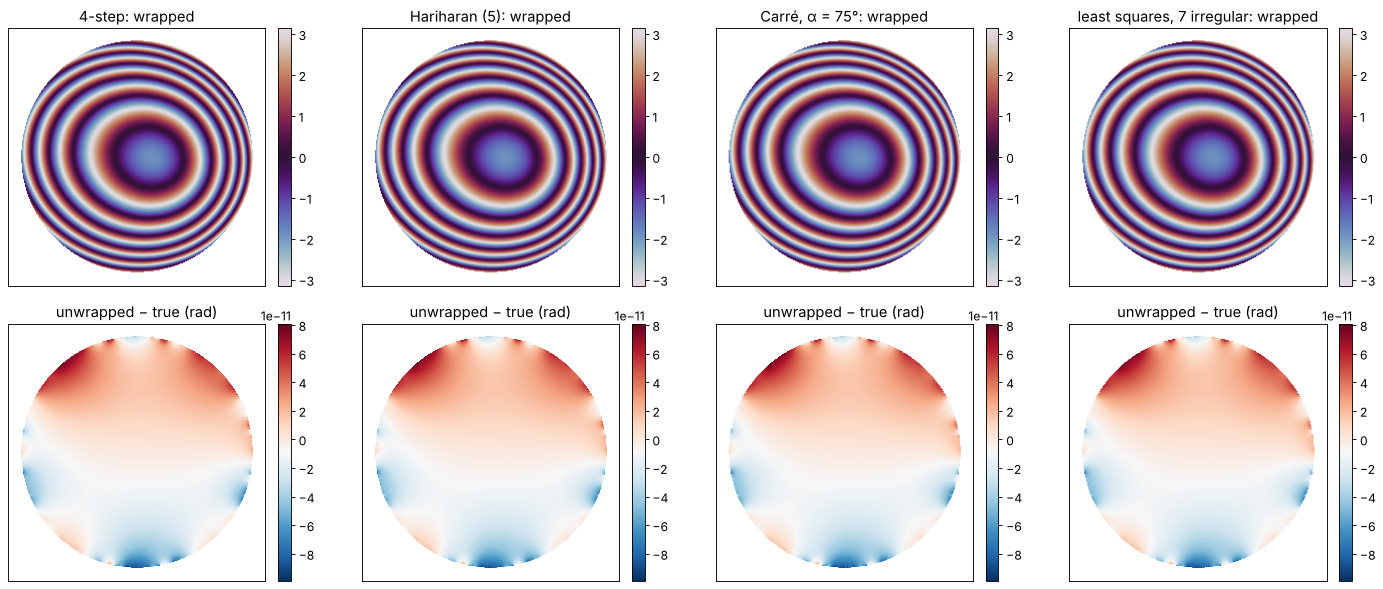

In [4]:
cases = {
    "4-step": (psi_4_step, phase_shifts(4)),
    "Hariharan (5)": (psi_hariharan, phase_shifts(5, np.pi/2, -np.pi)),
    "Carré, α = 75°": (psi_carre, phase_shifts(4, np.radians(75), -1.5*np.radians(75))),
    "least squares, 7 irregular": (None, np.sort(np.random.default_rng(3).uniform(0, 2*np.pi, 7))),
}

fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
results = {}
for i, (name, (func, sh)) in enumerate(cases.items()):
    fr = interferogram(phi, visibility=gamma_true, shift=sh)
    if func is None:
        psi, gam = psi_n_step(fr, sh)
    else:
        psi, gam = func(fr)
    u = unwrap_ls(nan_outside(psi, pupil), mask=pupil)
    err = u - phi
    err -= err[pupil].mean()
    results[name] = u
    show(axes[0, i], nan_outside(psi, pupil), name + ": wrapped", cmap="twilight")
    show(axes[1, i], nan_outside(err, pupil), "unwrapped − true (rad)", cmap="RdBu_r")
    print("%-28s max error %.1e rad, modulation %.4f" % (name, np.abs(err[pupil]).max(), gam[pupil].mean()))
plt.tight_layout()

print("Carré's estimated step: %.4f°" % np.degrees(psi_carre(
    interferogram(phi, shift=cases["Carré, α = 75°"][1]), return_step=True)[2]))

In [5]:
Z = FringeZernikes(x, y, R_norm=0.9)
idx = list(range(1, 10))
fit = Z.coeffs_from_field(np.nan_to_num(results["4-step"])/(2*np.pi), idx)
print(" j   true (waves)   fit (waves)")
for j, c in zip(idx, fit):
    if j > 1:   # piston is arbitrary
        print("%2d   %10.6f   %11.6f" % (j, coeffs.get(j, 0.0), c))

 j   true (waves)   fit (waves)
 2     0.000000      0.000000
 3     0.000000      0.000000
 4     2.500000      2.500000
 5    -0.600000     -0.600000
 6     0.300000      0.300000
 7     0.400000      0.400000
 8     0.000000     -0.000000
 9     0.250000      0.250000


## 3. Phase shifter miscalibration

A real phase shifter (a piezo moving the reference mirror) never moves
exactly as commanded. With a linear calibration error
$\delta_j' = \delta_j(1 + \varepsilon)$, the four-bucket algorithm produces a
phase error that oscillates at twice the fringe frequency ("print-through"
of the fringes) with an amplitude proportional to $\varepsilon$, plus a
harmless piston. Hariharan's
five-frame algorithm was designed to cancel the first order, so its error
grows only with $\varepsilon^2$. Carré's algorithm estimates the actual step
and is immune to a linear error, but it is more sensitive to noise (Section
4). `shift_error_sensitivity()` computes the rms error over all phases.

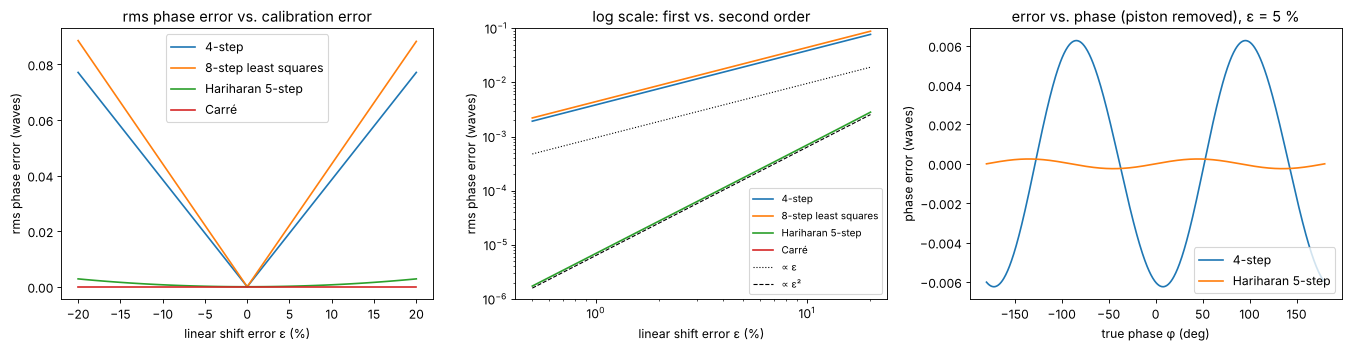

In [6]:
eps = np.linspace(-0.2, 0.2, 81)
algos = [("4-step", {}), ("n-step", dict(N=8)), ("hariharan", {}), ("carre", {})]
labels = {"4-step": "4-step", "n-step": "8-step least squares", "hariharan": "Hariharan 5-step",
          "carre": "Carré"}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for name, kw in algos:
    rms = shift_error_sensitivity(name, eps, **kw)
    axes[0].plot(100*eps, rms/(2*np.pi), label=labels[name])
    axes[1].loglog(100*eps[eps > 0], rms[eps > 0]/(2*np.pi), label=labels[name])
for ax in axes[:2]:
    ax.set_xlabel("linear shift error ε (%)"); ax.set_ylabel("rms phase error (waves)")
axes[1].loglog(100*eps[eps > 0], 0.6*eps[eps > 0]/(2*np.pi), "k:", lw=1, label="∝ ε")
axes[1].loglog(100*eps[eps > 0], 0.4*eps[eps > 0]**2/(2*np.pi), "k--", lw=1, label="∝ ε²")
axes[1].set_ylim(1E-6, 1E-1)
axes[0].legend(); axes[1].legend(fontsize=9)
axes[0].set_title("rms phase error vs. calibration error")
axes[1].set_title("log scale: first vs. second order")

# phase error vs. phase for ε = 5 %: the 2φ ripple
p = np.linspace(-np.pi, np.pi, 721)
for name, func, n, centered in [("4-step", psi_4_step, 4, False),
                                ("Hariharan 5-step", psi_hariharan, 5, True)]:
    sh = phase_shifts(n, np.pi/2, -(n - 1)*np.pi/4 if centered else 0.0, linear_error=0.05)
    rec = func(interferogram(p, shift=sh))[0]
    e = wrap(rec - p)
    axes[2].plot(np.degrees(p), (e - e.mean())/(2*np.pi), label=name)
axes[2].set_xlabel("true phase φ (deg)"); axes[2].set_ylabel("phase error (waves)")
axes[2].set_title("error vs. phase (piston removed), ε = 5 %"); axes[2].legend()
plt.tight_layout()

The ripple at twice the fringe frequency is what one sees in a measured
wavefront when the phase shifter is off: the fringe pattern prints through.
In the wavefront below, the shifter moves 5 % too far.

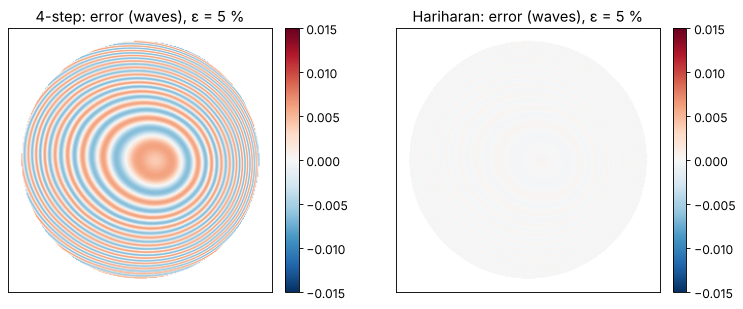

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, func, n, centered) in zip(axes, [("4-step", psi_4_step, 4, False),
                                                ("Hariharan", psi_hariharan, 5, True)]):
    sh = phase_shifts(n, np.pi/2, -(n - 1)*np.pi/4 if centered else 0.0, linear_error=0.05)
    psi = func(interferogram(phi, shift=sh))[0]
    err = wrap(psi - phi)
    err -= np.median(err[pupil])   # the shift error also adds a harmless piston
    show(ax, nan_outside(err/(2*np.pi), pupil), name + ": error (waves), ε = 5 %",
         cmap="RdBu_r", vmin=-0.015, vmax=0.015)
plt.tight_layout()

## 4. Camera noise

With photon shot noise only, the phase noise of an $N$-frame algorithm with
equally spaced shifts is $\sigma_\varphi = 1/(\gamma\sqrt{N I_0/2})$, where $I_0$
is the mean number of photons per pixel and frame. The frames go through a
`CameraNoiser` (Poisson model). Carré's algorithm divides by small numbers
where $\sin\varphi$ or $\cos\varphi$ vanish and is several times noisier.

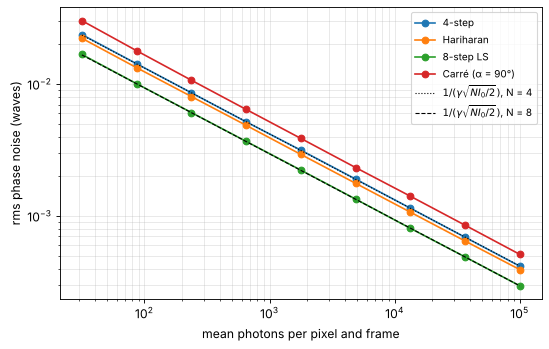

In [8]:
photons = np.logspace(1.5, 5, 9)
algos = {"4-step": (psi_4_step, phase_shifts(4)),
         "Hariharan": (psi_hariharan, phase_shifts(5, np.pi/2, -np.pi)),
         "8-step LS": (lambda f: psi_n_step(f, phase_shifts(8)), phase_shifts(8)),
         "Carré (α = 90°)": (psi_carre, phase_shifts(4, np.pi/2, -3*np.pi/4))}
noiser = CameraNoiser("poisson", rng=1)
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, (func, sh) in algos.items():
    sig = []
    for I0 in photons:
        fr = interferogram(phi, visibility=gamma_true, shift=sh, I0=I0, noiser=noiser)
        sig.append(np.std(wrap(func(fr)[0] - phi)[pupil]))
    ax.loglog(photons, np.array(sig)/(2*np.pi), "o-", label=name)
for n, ls in [(4, ":"), (8, "--")]:
    ax.loglog(photons, 1/(gamma_true*np.sqrt(n*photons/2))/(2*np.pi), "k" + ls, lw=1,
              label=r"$1/(\gamma\sqrt{N I_0/2})$, N = %d" % n)
ax.set_xlabel("mean photons per pixel and frame"); ax.set_ylabel("rms phase noise (waves)")
ax.legend(fontsize=9); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()

(The Hariharan algorithm weights its five frames unequally, so it sits
slightly above the 4-frame limit for its $N = 5$.)

## 5. Fourier-transform method (Takeda)

A single frame suffices if the reference is tilted: the carrier $k_c$ turns
the fringes into a nearly periodic pattern
$I = a + c\,e^{i\mathbf{k}_c\cdot\mathbf{r}} + c^*e^{-i\mathbf{k}_c\cdot\mathbf{r}}$ with
$c = \tfrac{b}{2}e^{i\varphi}$. In the spectrum, $c$ forms a sideband around
$k_c$. A window around $k_c$ (radius $|k_c|/2$ by default) isolates it; the
inverse transform times $e^{-i\mathbf{k}_c\cdot\mathbf{r}}$ gives $c$, hence
$\varphi$ and $\gamma$. `find_carrier()` locates the sideband as the centroid
of the power spectrum around its peak (give it the pupil mask, otherwise the
pupil edge can outshine the sideband).

carrier: found (95.96, 25.14), true (94.25, 25.13) rad/unit


rms error: 0.0113 waves, inside r < 0.8: 0.0054 waves


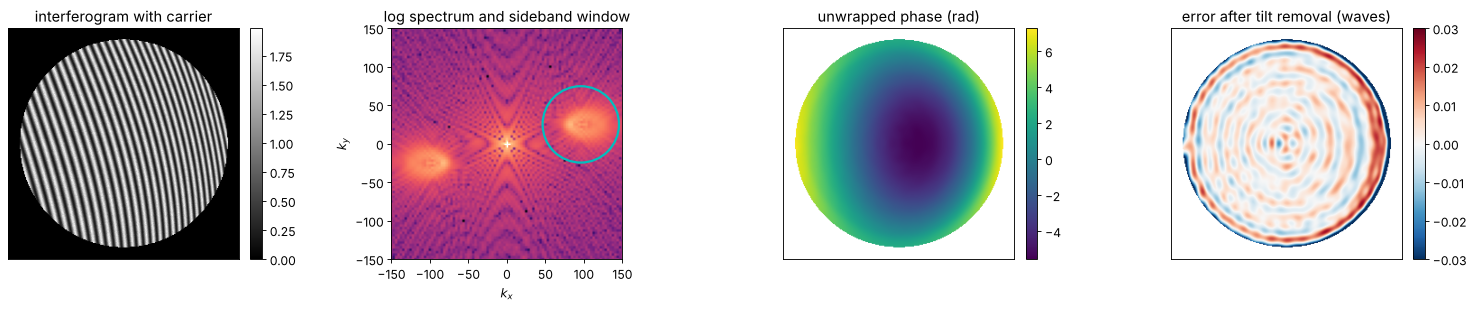

In [9]:
phi_t, pupil_t = zernike_phase(x, y, [0, 0, 0, 0.8, 0.4, 0, 0.3], 0.9)
kc_true = (2*np.pi*30/2, 2*np.pi*8/2)          # 30 and 8 fringes across the field
I = interferogram(phi_t, x, y, visibility=0.8, carrier=kc_true) * pupil_t
I = CameraNoiser("poisson", rng=4)(500*I)/500        # 500 photons

kc = find_carrier(I, x, y, mask=pupil_t)
print("carrier: found (%.2f, %.2f), true (%.2f, %.2f) rad/unit" % (kc + kc_true))
psi, gam = fourier_fringe_analysis(I, x, y, carrier=kc, mask=pupil_t)
u = unwrap_ls(nan_outside(psi, pupil_t), mask=pupil_t)

# remove piston and tilt (the found carrier may differ slightly from the true one)
A = np.stack([np.ones(pupil_t.sum()), X[pupil_t], Y[pupil_t]], axis=1)
d = (u - phi_t)[pupil_t]
d -= A @ np.linalg.lstsq(A, d, rcond=None)[0]
err = np.full_like(u, np.nan); err[pupil_t] = d

KX, KY = freq_grid(x, y)
S = np.abs(FT(I - I[pupil_t].mean()))
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
show(axes[0], I, "interferogram with carrier", cmap="gray")
im = axes[1].imshow(np.log10(S + S.max()*1E-6), extent=(KX[0, 0], KX[0, -1], KY[0, 0], KY[-1, 0]),
                    cmap="magma")
axes[1].add_patch(plt.Circle(kc, np.hypot(*kc)/2, fill=False, color="c", lw=2))
axes[1].plot(0, 0, "w+"); axes[1].set_xlim(-150, 150); axes[1].set_ylim(-150, 150)
axes[1].set_title("log spectrum and sideband window"); axes[1].set_xlabel("$k_x$"); axes[1].set_ylabel("$k_y$")
show(axes[2], nan_outside(u, pupil_t), "unwrapped phase (rad)")
show(axes[3], err/(2*np.pi), "error after tilt removal (waves)", cmap="RdBu_r", vmin=-0.03, vmax=0.03)
plt.tight_layout()
print("rms error: %.4f waves, inside r < 0.8: %.4f waves" % (np.nanstd(err)/(2*np.pi),
      np.nanstd(np.where(np.hypot(X, Y) < 0.8, err, np.nan))/(2*np.pi)))

The errors concentrate at the pupil edge: the abrupt end of the fringes
spreads the sideband (leakage), and the window cuts off part of it. Inside the
pupil, the error is set by the shot noise. The `mask` argument fills the
region outside the pupil with the mean intensity before the transform and
sets the outputs there to zero.

### Spectral overlap: how large must the carrier be?

The sideband extends over $k_c \pm \max|\nabla\varphi|$. It must stay clear
of the zero order and of the $-1$ order, otherwise the window catches parts of
them. Below, the same wavefront is analysed with ever smaller carriers. The
function warns when the window holds less than 90 % of the sideband power.
The dashed line marks the carrier at which the steepest local phase gradient
equals $|k_c|/2$.

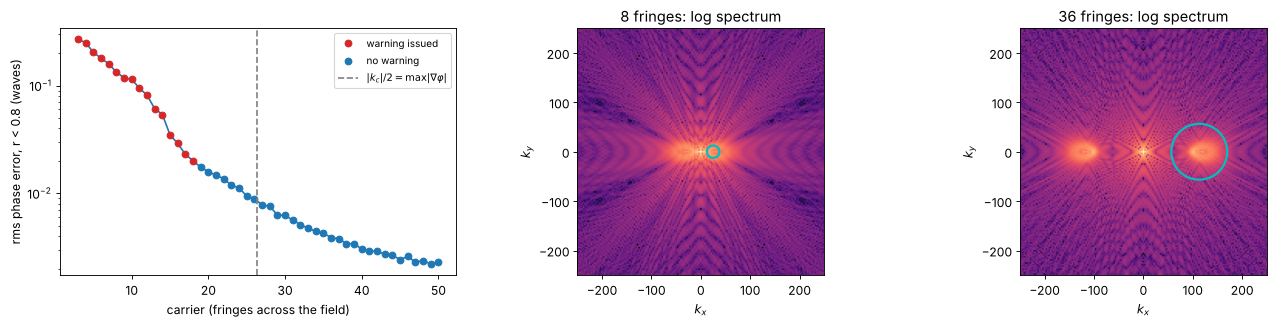

In [10]:
grad_max = np.max(np.hypot(*np.gradient(phi_t, y, x))[binary_erosion(pupil_t, iterations=2)])
fringes = np.arange(3, 51)
rms, warned = [], []
inner = np.hypot(X, Y) < 0.8
for nf in fringes:
    kc_n = (2*np.pi*nf/2, 0.0)
    I_n = interferogram(phi_t, x, y, visibility=0.8, carrier=kc_n) * pupil_t
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        p, _ = fourier_fringe_analysis(I_n, x, y, carrier=kc_n, mask=pupil_t)
    warned.append(any("sideband power" in str(wi.message) for wi in w))
    rms.append(np.sqrt(np.mean(wrap(p - phi_t)[inner]**2)))
rms, warned = np.array(rms)/(2*np.pi), np.array(warned)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].semilogy(fringes, rms, "-", color="C0")
axes[0].semilogy(fringes[warned], rms[warned], "o", color="C3", label="warning issued")
axes[0].semilogy(fringes[~warned], rms[~warned], "o", color="C0", label="no warning")
axes[0].axvline(2*grad_max/(2*np.pi/2), color="gray", ls="--", label=r"$|k_c|/2 = \max|\nabla\varphi|$")
axes[0].set_xlabel("carrier (fringes across the field)"); axes[0].set_ylabel("rms phase error, r < 0.8 (waves)")
axes[0].legend(fontsize=9)
for ax, nf in zip(axes[1:], [8, 36]):
    kc_n = (2*np.pi*nf/2, 0.0)
    I_n = interferogram(phi_t, x, y, visibility=0.8, carrier=kc_n) * pupil_t
    S_n = np.abs(FT(I_n - I_n[pupil_t].mean()))
    ax.imshow(np.log10(S_n + S_n.max()*1E-5), extent=(KX[0, 0], KX[0, -1], KY[0, 0], KY[-1, 0]), cmap="magma")
    ax.add_patch(plt.Circle(kc_n, np.hypot(*kc_n)/2, fill=False, color="c", lw=2))
    ax.set_xlim(-250, 250); ax.set_ylim(-250, 250)
    ax.set_title("%d fringes: log spectrum" % nf); ax.set_xlabel("$k_x$"); ax.set_ylabel("$k_y$")
plt.tight_layout()

### Window shape and apodization

The default top-hat window keeps the sideband unattenuated, so the
modulation comes out right. Tapered windows (`"hann"`, `"gaussian"`) ring
less but attenuate the outer parts of a broad sideband, which biases
$\gamma$ low where the fringes are dense. Apodizing the frame with a Tukey
window (`apodize`) reduces the ringing that the edges of a full-field
interferogram cause in the interior, at the expense of the tapered border.
Here the fringes fill the whole frame (no pupil), which is the worst case for
leakage.

tophat                 rms error r < 0.5: 2.69e-03 waves, median modulation 0.799
hann                   rms error r < 0.5: 9.99e-05 waves, median modulation 0.771
gaussian               rms error r < 0.5: 1.51e-04 waves, median modulation 0.776
tophat, apodize 0.5    rms error r < 0.5: 2.65e-04 waves, median modulation 0.800


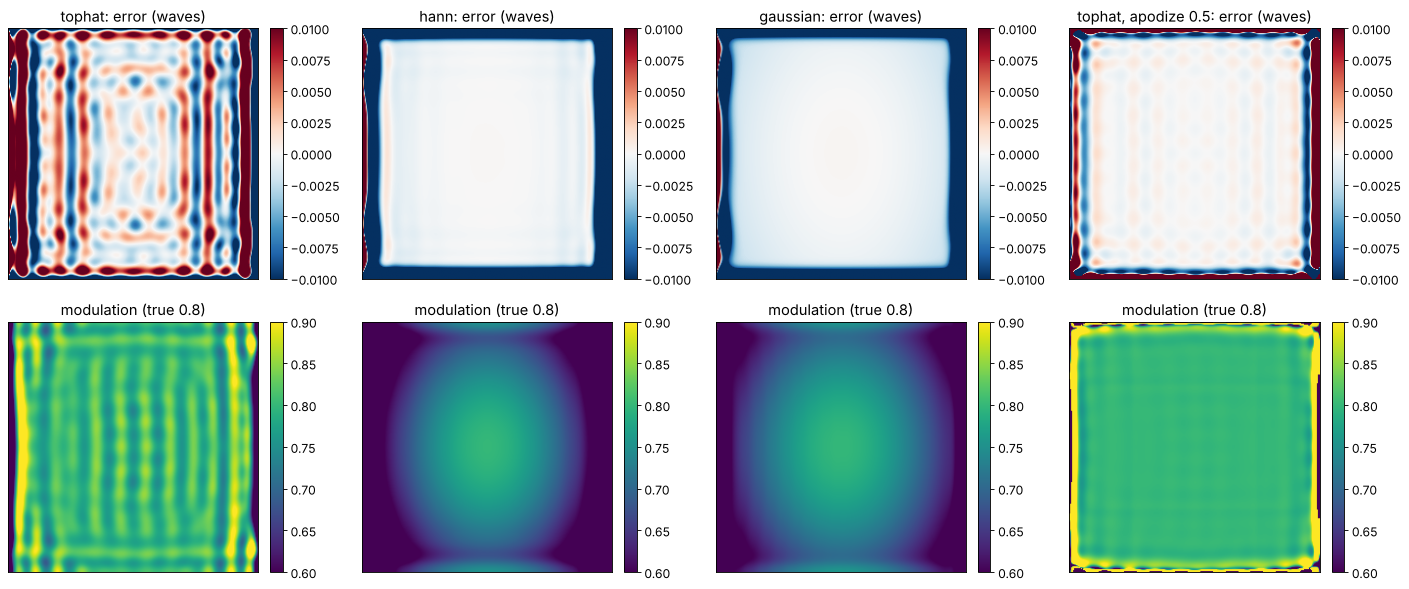

In [11]:
phi_f, _ = zernike_phase(x, y, [0, 0, 0, 1.0, 0.3], 1.5)
kc_f = (2*np.pi*20.4/2, 0.0)   # non-integer number of fringes: not periodic
I_f = interferogram(phi_f, x, y, visibility=0.8, carrier=kc_f)
cases = [("tophat", 0.0), ("hann", 0.0), ("gaussian", 0.0), ("tophat", 0.5)]
fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
for i, (win, ap) in enumerate(cases):
    p, g = fourier_fringe_analysis(I_f, x, y, carrier=kc_f, window=win, apodize=ap)
    e = wrap(p - phi_f)
    e -= np.median(e[np.hypot(X, Y) < 0.5])   # piston
    title = "%s%s" % (win, ", apodize %.1f" % ap if ap else "")
    show(axes[0, i], e/(2*np.pi), title + ": error (waves)", cmap="RdBu_r", vmin=-0.01, vmax=0.01)
    show(axes[1, i], g, "modulation (true 0.8)", vmin=0.6, vmax=0.9)
    c = np.hypot(X, Y) < 0.5
    print("%-22s rms error r < 0.5: %.2e waves, median modulation %.3f" %
          (title, np.std(e[c])/(2*np.pi), np.median(g[c])))
plt.tight_layout()

## Summary

* Use phase shifting whenever the setup allows several frames: the phase is
  exact without noise, pixel by pixel, without any spatial filtering.
  Prefer algorithms that tolerate the dominant error: Hariharan's five
  frames for shifter calibration errors, more frames against noise (the
  phase noise falls with $1/\sqrt{N I_0}$), Carré if the step is unknown and
  the light level is high.
* The Fourier-transform method needs a single frame (vibration-insensitive,
  dynamic measurements) but a carrier large enough to separate the orders,
  $|k_c|/2 > \max|\nabla\varphi|$, and it smooths the phase and loses
  accuracy at the edges.
* Both give the wrapped phase; unwrap it with `pyoptics.unwrap`, then fit
  Zernikes with `pyoptics.bases`.